Successfully loaded model from /kaggle/input/models/ashutoshbhate/conversion-model/pytorch/default/1/G_AB_95.pth


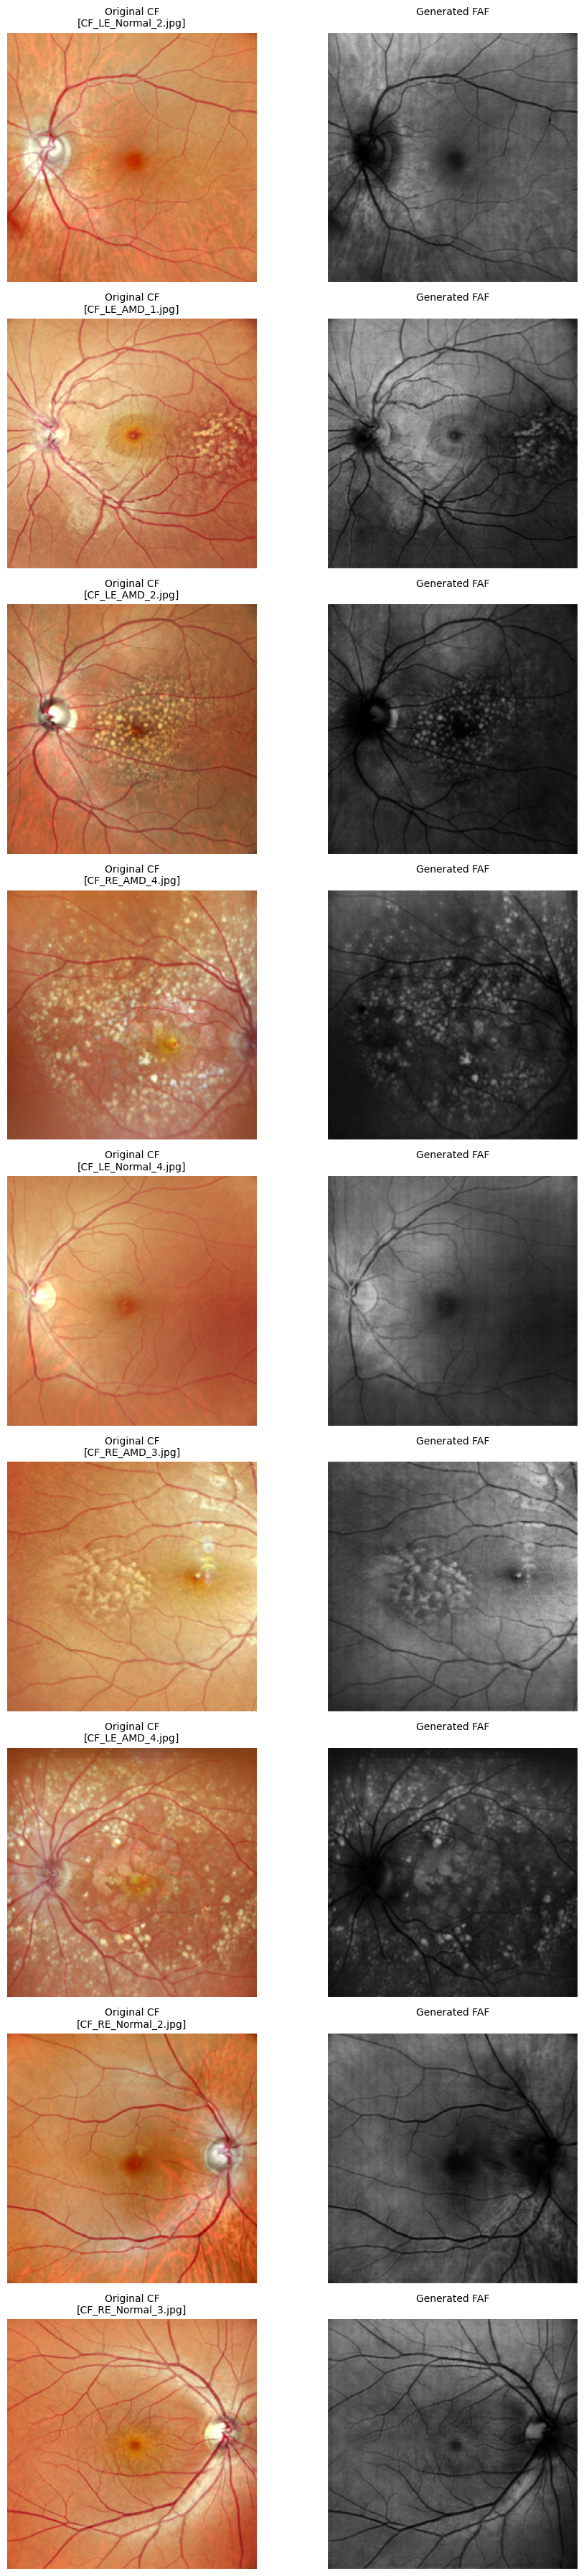

<Figure size 640x480 with 0 Axes>

In [3]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import os
import glob
import random

# ==========================================
# 1. RE-DEFINE THE ARCHITECTURE
# (Must match exactly what was used for training: U-Net)
# ==========================================
class Block(nn.Module):
    def __init__(self, in_channels, out_channels, down=True, act="relu", use_dropout=False):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=False, padding_mode="reflect")
            if down
            else nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU() if act == "relu" else nn.LeakyReLU(0.2),
        )
        self.use_dropout = use_dropout
        self.dropout = nn.Dropout(0.5)
    def forward(self, x):
        x = self.conv(x)
        return self.dropout(x) if self.use_dropout else x
    
class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, features=48): # NOTE: features=48 matches training!
        super().__init__()
        self.initial_down = nn.Sequential(
            nn.Conv2d(in_channels, features, 4, 2, 1, padding_mode="reflect"),
            nn.LeakyReLU(0.2),
        )
        self.down1 = Block(features, features * 2, down=True, act="leaky")
        self.down2 = Block(features * 2, features * 4, down=True, act="leaky")
        self.down3 = Block(features * 4, features * 8, down=True, act="leaky")
        self.down4 = Block(features * 8, features * 8, down=True, act="leaky")
        self.down5 = Block(features * 8, features * 8, down=True, act="leaky")
        self.down6 = Block(features * 8, features * 8, down=True, act="leaky")
        self.bottleneck = nn.Sequential(
            nn.Conv2d(features * 8, features * 8, 4, 2, 1, padding_mode="reflect"),
            nn.ReLU()
        )
        self.up1 = Block(features * 8, features * 8, down=False, act="relu", use_dropout=True)
        self.up2 = Block(features * 8 * 2, features * 8, down=False, act="relu", use_dropout=True)
        self.up3 = Block(features * 8 * 2, features * 8, down=False, act="relu", use_dropout=True)
        self.up4 = Block(features * 8 * 2, features * 8, down=False, act="relu")
        self.up5 = Block(features * 8 * 2, features * 4, down=False, act="relu")
        self.up6 = Block(features * 4 * 2, features * 2, down=False, act="relu")
        self.up7 = Block(features * 2 * 2, features, down=False, act="relu")
        self.final_up = nn.Sequential(
            nn.ConvTranspose2d(features * 2, in_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )
    def forward(self, x):
        d1 = self.initial_down(x)
        d2 = self.down1(d1)
        d3 = self.down2(d2)
        d4 = self.down3(d3)
        d5 = self.down4(d4)
        d6 = self.down5(d5)
        d7 = self.down6(d6)
        bottleneck = self.bottleneck(d7)
        up1 = self.up1(bottleneck)
        up2 = self.up2(torch.cat([up1, d7], 1))
        up3 = self.up3(torch.cat([up2, d6], 1))
        up4 = self.up4(torch.cat([up3, d5], 1))
        up5 = self.up5(torch.cat([up4, d4], 1))
        up6 = self.up6(torch.cat([up5, d3], 1))
        up7 = self.up7(torch.cat([up6, d2], 1))
        return self.final_up(torch.cat([up7, d1], 1))



# ==========================================
# 2. SETUP & LOAD MODEL
# ==========================================

# --- CONFIG ---
# UPDATE THIS PATH to where you uploaded the .pth file
MODEL_PATH = "/kaggle/input/models/ashutoshbhate/conversion-model/pytorch/default/1/G_AB_95.pth"
# UPDATE THIS PATH to where your CF images are
CF_IMAGE_DIR = "/kaggle/input/datasets/ashutoshbhate/cyclegan-test/cycleGAN_Test" 

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize Model
generator = UNetGenerator(in_channels=3, features=48).to(device)

# Load Weights
try:
    generator.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    print(f"Successfully loaded model from {MODEL_PATH}")
    generator.eval() # Set to evaluation mode (important for InstanceNorm)
except FileNotFoundError:
    print(f"ERROR: Could not find model at {MODEL_PATH}. Please check the path.")

# ==========================================
# 3. RUN VISUALIZATION
# ==========================================

def run_test(num_samples=9):
    # Get random images from the CF folder
    all_files = sorted(glob.glob(os.path.join(CF_IMAGE_DIR, "*.*")))
    
    if len(all_files) == 0:
        print("ERROR: No images found in CF_IMAGE_DIR. Check the path.")
        return

    # Select random samples
    sample_files = random.sample(all_files, min(num_samples, len(all_files)))
    
    # Define Transform (Must match training: Resize -> Normalize)
    transform = transforms.Compose([
        transforms.Resize((256, 256), Image.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    plt.figure(figsize=(10, num_samples * 4))

    for i, img_path in enumerate(sample_files):
        # Extract the actual file name
        filename = os.path.basename(img_path)
        
        # Load and Preprocess
        img_pil = Image.open(img_path).convert('RGB')
        img_tensor = transform(img_pil).unsqueeze(0).to(device) # Add batch dim
        
        # Inference
        with torch.no_grad():
            fake_faf = generator(img_tensor)
        
        # Denormalize for plotting
        real_img = img_tensor[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        fake_img = fake_faf[0].cpu().permute(1, 2, 0) * 0.5 + 0.5
        
        # Plotting
        plt.subplot(num_samples, 2, 2*i + 1)
        plt.imshow(real_img)
        # Display the filename right below "Original CF"
        plt.title(f"Original CF\n[{filename}]", fontsize=10) 
        plt.axis('off')
        
        plt.subplot(num_samples, 2, 2*i + 2)
        plt.imshow(fake_img, cmap='gray') 
        plt.title("Generated FAF\n", fontsize=10) # Added a newline to keep heights aligned
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    plt.tight_layout()
    plt.show()

# Run it!
run_test(num_samples=9)